# EA4 PGS Run — Predicted Conditions vs Observed Correlations

The NPE fits of conditions 01–04 (fit to the observed PGS **and** phenotypic correlations; the v2
fits of October 2026, not retrained) were applied to the PGS correlations of the updated EA4 PGS
(`observed_correlations_PGS_ea4new.csv`). Each condition was then simulated at the posterior means
(`Scripts/run_rc_paper/run_predicted_condition_rc_*.py`, 100 replicates, compiled with
`compile_predicted_condition.py`), and this notebook compares the simulated relative correlations with
the observed ones. The full comparison with the v1 and v2 runs is in `Analysis_NPE.ipynb`.

**Observed data.** The EA4 file has 26 relationship types: the 16 the NPE fits use, and 10 more
(`SC`, `PSCC`, `MPS`, `MSCM`, `SMPS`, `MPSC`, `SCMP`, `MPSCM`, `MSMPS`, `SMSCM`) that were never in the
training data, so they test the fitted models out of sample. The phenotypic correlations are
unchanged (`observed_correlations_pheno.csv`, the 16 fit types).

**Reading the figures.** For each relationship type, the bars are the simulated PGS correlations
(blue) and phenotypic correlations (teal; error bars: SD across the 100 replicates); the diamond on each
bar is the observed value. The 16 types the fits use are on the left of the dashed line, the 10 new
types on the right; each group is sorted by the observed PGS correlation. The box gives MAE, RMSE and r
for each group; the table under the figure adds the bias (simulated − observed).

**Results in short.**
- **01 and 04** reproduce the PGS correlations closely, the 10 new types almost as well as the fit types.
- **02** over-predicts the PGS correlations by about 0.03 on average and the phenotypic ones by about 0.09.
- **03** fits poorly: PGS correlations about 0.09 too high and phenotypic ones about 0.2 too high. The
  [last section](#why-condition-03-fits-poorly) shows why: the model cannot produce EA's phenotypic
  pattern, and the NPE estimate it returns is far from its best-fitting simulations.

Parameter meanings, the simulation model and the NPE are documented in the repository `README.md`.
`vg` sets the *environmental* variance (1 − `vg`); the genetic variance is ≈ 1, so founder heritability
is ≈ 1/(2 − `vg`).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from pathlib import Path

# ── Paths and observed data ────────────────────────────────────────────────
script_dir = Path(".")
obs_pgs = pd.read_csv(script_dir / "observed_correlations_PGS_ea4new.csv").set_index("RelType")["Correlation"]
obs_pgs_old = pd.read_csv(script_dir / "observed_correlations_PGS.csv").set_index("RelType")["Correlation"]
obs_pheno = pd.read_csv(script_dir / "observed_correlations_pheno.csv").set_index("RelType")["Correlation"]

# the 16 relationship types the NPE fits use, and the 10 EA4 types not in the training data
TRAINING_TYPES = [t for t in obs_pgs_old.index if t in obs_pgs.index]
NEW_TYPES = [t for t in obs_pgs.index if t not in obs_pgs_old.index]
print(f"{len(TRAINING_TYPES)} fit types: {TRAINING_TYPES}")
print(f"{len(NEW_TYPES)} new types: {NEW_TYPES}")


def pred_path(fit, suffix="_ea4new"):
    """Predicted-condition summary file (v2: suffix _v2; condition 04's old-PGS run: no suffix)."""
    return script_dir / f"results_npe_unweighted_{fit}" / "predictions" / f"summary_statistics_{fit}{suffix}.csv"


# condition -> NPE fit(s) giving its parameters, folder of its summary file, compared trait(s), and
# the suffix of its old-PGS (v2) summary file
CONDITIONS = {
    "01DirAM": dict(title="Condition 01 — Direct AM", fits=["01DirAM_AE", "01DirAM_AFE"],
                    summary="01DirAM_AE", old_suffix="_v2",
                    traits=[(1, "Trait 1 (AE)"), (2, "Trait 2 (AFE)")]),
    "02AElatentAM": dict(title="Condition 02 — AE latent AM", fits=["02AElatentAM"],
                         summary="02AElatentAM", old_suffix="_v2", traits=[(1, "Trait 1 (EA)")]),
    "03EnvLatentAM": dict(title="Condition 03 — Environmental latent AM", fits=["03EnvLatentAM"],
                          summary="03EnvLatentAM", old_suffix="_v2", traits=[(1, "Trait 1 (EA)")]),
    "04EAmigration": dict(title="Condition 04 — EA-driven migration", fits=["04EAmigration"],
                          summary="04EAmigration", old_suffix="", traits=[(1, "Trait 1 (EA)")]),
}

MEANING = {
    "prop_h2_latent1": "share of trait-1 genetic variance not captured by the PGS",
    "prop_h2_latent2": "share of trait-2 genetic variance not captured by the PGS",
    "vg1": "sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1))",
    "vg2": "sets the trait-2 environmental variance 1 − vg2",
    "am11": "spousal correlation on trait 1",
    "am22": "spousal correlation on trait 2",
    "f11": "vertical transmission, trait 1",
    "f22": "vertical transmission, trait 2",
    "s22": "shared family environment, trait 2 (no effect: the engine ignores s)",
    "re": "environmental correlation between the traits",
    "rg": "genetic correlation between the traits",
    "move_p": "fraction of each sex per island migrating each generation",
    "n_gen": "generations since the random founders (categorical posterior)",
}

# bar colours as in Analysis_NPE.ipynb: PGS blue, phenotypic teal; ACCENT marks the EA4 estimate in
# the condition-03 figure (reference palette slots 1-3, validated as a set)
BAR_COLORS = {"PGS": "#2a78d6", "Phenotypic": "#199e70"}
ACCENT = "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"


def show(df, precision=4):
    display(df.style.hide(axis="index").format(precision=precision, na_rep="–"))


def parameter_table(key):
    """EA4 posterior of every estimated parameter, with its simulated range and the old-PGS (v2) value."""
    rows = []
    for fit in CONDITIONS[key]["fits"]:
        run = script_dir / f"results_npe_unweighted_{fit}"
        cfg = json.loads((run / "config.json").read_text())
        bounds = dict(zip(cfg["prior_params"], zip(cfg["prior_lower"], cfg["prior_upper"])))
        if cfg.get("count_param"):
            bounds[cfg["count_param"]] = (min(cfg["count_values"]), max(cfg["count_values"]))
        new = pd.read_csv(run / "predictions_ea4new" / "posterior_summary.csv").set_index("parameter")
        old = pd.read_csv(run / "predictions" / "posterior_summary.csv").set_index("parameter")
        sampling = json.loads((run / "predictions_ea4new" / "posterior_sampling.json").read_text())
        print(f"{fit}: {sampling['share_of_unconstrained_flow_inside_prior']:.1%} of the unrestricted "
              f"posterior inside the simulated range -> {sampling['sampling_method']} sampling "
              f"({sampling['n_samples']:,} draws)")
        for p, r in new.iterrows():
            lo, hi = bounds[p]
            rows.append({"NPE fit": fit, "parameter": p, "meaning": MEANING[p],
                         "EA4 estimate": r["mean"], "posterior SD": r["std"],
                         "95% interval": f"{r['ci_lower_2.5']:.3f} – {r['ci_upper_97.5']:.3f}",
                         "simulated range": f"{lo:.2f} – {hi:.2f}",
                         "position in range": f"{100 * (r['mean'] - lo) / (hi - lo):.0f}%",
                         "old PGS (v2)": old.loc[p, "mean"]})
    show(pd.DataFrame(rows))


def load_summary(csv_path):
    """Predicted-condition summary_statistics CSV -> one row per relationship type."""
    df = pd.read_csv(csv_path)
    wide = df.pivot(index="RelationshipPath", columns="Variable",
                    values=["Correlation_Mean", "Correlation_SD"])
    wide.columns = [f"{v}_{c}" for v, c in wide.columns]
    return wide


def errors(pred, obs, types):
    """MAE, RMSE, bias and r of simulated against observed correlations over `types`."""
    p, o = pred.reindex(types), obs.reindex(types)
    ok = p.notna() & o.notna()
    diff = p[ok] - o[ok]
    return {"n": int(ok.sum()), "MAE": diff.abs().mean(), "RMSE": np.sqrt((diff ** 2).mean()),
            "bias": diff.mean(), "r": np.corrcoef(p[ok], o[ok])[0, 1] if ok.sum() > 1 else np.nan}


def error_table(frame, trait):
    groups = (("PGS, 16 fit types", "PGS", obs_pgs, TRAINING_TYPES),
              ("PGS, 10 new types", "PGS", obs_pgs, NEW_TYPES),
              ("PGS, all 26 types", "PGS", obs_pgs, list(obs_pgs.index)),
              ("phenotypic, 16 fit types", "Y", obs_pheno, TRAINING_TYPES))
    return pd.DataFrame([{"correlations": label,
                          **errors(frame[f"Correlation_Mean_{var}{trait}"], obs, types)}
                         for label, var, obs, types in groups])


def error_box(ax, table):
    """Box in the top-right corner with MAE, RMSE and r of each group of correlations."""
    short = {"PGS, 16 fit types": "PGS, fit types", "PGS, 10 new types": "PGS, new types",
             "phenotypic, 16 fit types": "pheno"}
    lines = [f"{'':<15}{'MAE':>7}{'RMSE':>7}{'r':>7}"]
    for _, e in table[table["correlations"].isin(short)].iterrows():
        lines.append(f"{short[e['correlations']]:<15}{e['MAE']:>7.3f}{e['RMSE']:>7.3f}{e['r']:>7.3f}")
    ax.text(0.995, 0.97, "\n".join(lines), transform=ax.transAxes, ha="right", va="top",
            family="monospace", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="0.6", alpha=0.95))


def plot_condition(key):
    """
    One figure per compared trait: simulated PGS and phenotypic correlations of each relationship type
    at the EA4 estimates, the 16 fit types left of the dashed line and the 10 new types right of it,
    with the observed values as diamonds; the table below the figure gives the errors per group.
    """
    cond = CONDITIONS[key]
    frame = load_summary(pred_path(cond["summary"]))
    groups = [sorted(TRAINING_TYPES, key=lambda r: -obs_pgs[r]), sorted(NEW_TYPES, key=lambda r: -obs_pgs[r])]
    rel_types = groups[0] + groups[1]
    x = np.arange(len(rel_types))
    width = 0.42
    sub = frame.reindex(rel_types)
    print(f"{cond['title']}: {pred_path(cond['summary'])} "
          f"({int(pd.read_csv(pred_path(cond['summary']))['N_Iterations'].max())} replicates)")

    for trait, trait_label in cond["traits"]:
        fig, ax = plt.subplots(figsize=(22, 7))
        panels = (("PGS", f"PGS{trait}", obs_pgs, -width / 2), ("Phenotypic", f"Y{trait}", obs_pheno, width / 2))
        for i, (kind, var, obs, off) in enumerate(panels):
            ax.bar(x + off, sub[f"Correlation_Mean_{var}"], width, yerr=sub[f"Correlation_SD_{var}"],
                   capsize=2, error_kw=dict(lw=0.8, ecolor=MUTED), color=BAR_COLORS[kind],
                   edgecolor="white", linewidth=1.5, label=f"{kind} correlation (simulated)")
            ax.scatter(x + off, obs.reindex(rel_types), marker="D", s=110, facecolor="white",
                       edgecolor=INK, linewidth=1.5, zorder=5, label="Observed value" if i == 0 else None)
        table = error_table(frame, trait)
        error_box(ax, table)
        split = len(groups[0]) - 0.5
        ax.axvline(split, color=MUTED, linewidth=1, linestyle="--")
        for centre, text in ((np.mean([0, split]), f"Used by the NPE fit ({len(groups[0])} types)"),
                             (np.mean([split, len(rel_types) - 1]), f"Not in the training data ({len(groups[1])} types)")):
            ax.text(centre, 1.01, text, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                    fontsize=11, color=MUTED)
        ax.set_xlabel("Relationship type", fontsize=11)
        ax.set_ylabel("Correlation", fontsize=11)
        ax.set_xticks(x)
        ax.set_xticklabels(rel_types, rotation=45, ha="right")
        ax.set_xlim(-0.6, len(rel_types) - 0.4)
        ax.legend(loc="upper center", fontsize=10, ncol=3, frameon=True)
        ax.grid(axis="y", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.axhline(0, color=MUTED, linewidth=0.8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#c3c2b7")
        ax.tick_params(colors=MUTED)
        top = np.nanmax([ax.get_ylim()[1], *obs_pgs.reindex(rel_types), *obs_pheno.reindex(rel_types)])
        ax.set_ylim(top=top * 1.12)          # room for the legend and the error box
        plt.tight_layout()
        plt.show()
        print(f"\n{trait_label}: simulated vs observed")
        show(table)

16 fit types: ['S', 'PSC', 'PPSCC', 'M', 'MS', 'SMS', 'MSM', 'MSC', 'SMSC', 'SMSM', 'SMSMS', 'MSMSM', 'MSMSC', 'PSMSC', 'SMSMSC', 'MSMSMS']
10 new types: ['SC', 'PSCC', 'MPS', 'MSCM', 'SMPS', 'MPSC', 'SCMP', 'MPSCM', 'MSMPS', 'SMSCM']


## Overview

Errors of each predicted condition against the observed correlations, with the old-PGS (v2) run of the
same fit against the old observed PGS correlations for reference (16 fit types).

In [2]:
rows = []
for key, cond in CONDITIONS.items():
    frame = load_summary(pred_path(cond["summary"]))
    old = load_summary(pred_path(cond["summary"], cond["old_suffix"]))
    for trait, trait_label in cond["traits"]:
        e = error_table(frame, trait).set_index("correlations")
        rows.append({
            "condition": cond["title"], "trait": trait_label,
            "PGS MAE: 16 fit types": e.loc["PGS, 16 fit types", "MAE"],
            "PGS MAE: 10 new types": e.loc["PGS, 10 new types", "MAE"],
            "PGS bias: all 26": e.loc["PGS, all 26 types", "bias"],
            "PGS r: all 26": e.loc["PGS, all 26 types", "r"],
            "pheno MAE": e.loc["phenotypic, 16 fit types", "MAE"],
            "pheno bias": e.loc["phenotypic, 16 fit types", "bias"],
            "old PGS (v2): PGS MAE": errors(old[f"Correlation_Mean_PGS{trait}"], obs_pgs_old, TRAINING_TYPES)["MAE"],
            "old PGS (v2): pheno MAE": errors(old[f"Correlation_Mean_Y{trait}"], obs_pheno, TRAINING_TYPES)["MAE"],
        })
show(pd.DataFrame(rows))

condition,trait,PGS MAE: 16 fit types,PGS MAE: 10 new types,PGS bias: all 26,PGS r: all 26,pheno MAE,pheno bias,old PGS (v2): PGS MAE,old PGS (v2): pheno MAE
Condition 01 — Direct AM,Trait 1 (AE),0.0231,0.0322,-0.0206,0.9858,0.0578,-0.0526,0.0245,0.0576
Condition 01 — Direct AM,Trait 2 (AFE),0.0217,0.0322,-0.0188,0.9853,0.0567,-0.0488,0.0225,0.0564
Condition 02 — AE latent AM,Trait 1 (EA),0.0276,0.0348,0.0299,0.9817,0.0862,0.0862,0.0141,0.0825
Condition 03 — Environmental latent AM,Trait 1 (EA),0.0904,0.0973,0.0930,0.9619,0.2187,0.2187,0.0892,0.1788
Condition 04 — EA-driven migration,Trait 1 (EA),0.0156,0.0158,-0.0022,0.9870,0.0289,0.0158,0.0201,0.0284


## Condition 01 — Direct AM (trait 1 AE, trait 2 AFE)

Two independent traits (`rg = re = 0`), each with direct phenotypic assortative mating (bivariate AM
matrix without cross-trait terms). Trait 1 is an AE model; trait 2 is an AFE model with vertical
transmission (`f22`) and social homogamy (`s22`, which the engine ignores). Each trait is estimated by its
own univariate NPE: trait 1 by `01DirAM_AE`, trait 2 by `01DirAM_AFE`. Both traits are therefore
compared with the same observed EA correlations.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `f11`, `f12`, `f21` | vertical transmission | 0 |
| `s11`, `s12`, `s21` | shared family environment (no effect: the engine ignores `s`) | 0 |
| `am12`, `am21` | cross-trait assortative mating | 0 |
| `rg`, `re` | genetic and environmental correlation between the traits | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 15 (analysed 12–14) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; *position in range*: 0% = lower, 100% = upper end of the simulated range):

In [3]:
parameter_table("01DirAM")

01DirAM_AE: 50.4% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)
01DirAM_AFE: 0.0% of the unrestricted posterior inside the simulated range -> mcmc sampling (20,000 draws)


NPE fit,parameter,meaning,EA4 estimate,posterior SD,95% interval,simulated range,position in range,old PGS (v2)
01DirAM_AE,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.5432,0.0329,0.485 – 0.609,0.20 – 0.90,49%,0.6108
01DirAM_AE,vg1,sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1)),0.2158,0.0162,0.200 – 0.258,0.20 – 0.80,3%,0.2139
01DirAM_AE,am11,spousal correlation on trait 1,0.4373,0.0048,0.429 – 0.445,0.10 – 0.80,48%,0.4369
01DirAM_AFE,prop_h2_latent2,share of trait-2 genetic variance not captured by the PGS,0.5505,0.0305,0.490 – 0.607,0.20 – 0.90,50%,0.6242
01DirAM_AFE,am22,spousal correlation on trait 2,0.4409,0.0069,0.430 – 0.450,0.10 – 0.80,49%,0.4381
01DirAM_AFE,f22,"vertical transmission, trait 2",0.0023,0.0080,0.000 – 0.008,0.00 – 0.50,0%,0.0077
01DirAM_AFE,vg2,sets the trait-2 environmental variance 1 − vg2,0.2428,0.0482,0.206 – 0.358,0.20 – 0.80,7%,0.2798
01DirAM_AFE,s22,"shared family environment, trait 2 (no effect: the engine ignores s)",0.2613,0.1414,0.018 – 0.482,0.00 – 0.50,52%,0.2743


Almost none of the unrestricted trait-2 (`01DirAM_AFE`) posterior lies inside the simulated range, so
its estimates come from the range-restricted MCMC. `vg1`, `vg2` and `f22` sit at the lower end of their
ranges (the wider-prior design extends them); `s22` has no effect on the simulation.

Condition 01 — Direct AM: results_npe_unweighted_01DirAM_AE/predictions/summary_statistics_01DirAM_AE_ea4new.csv (100 replicates)


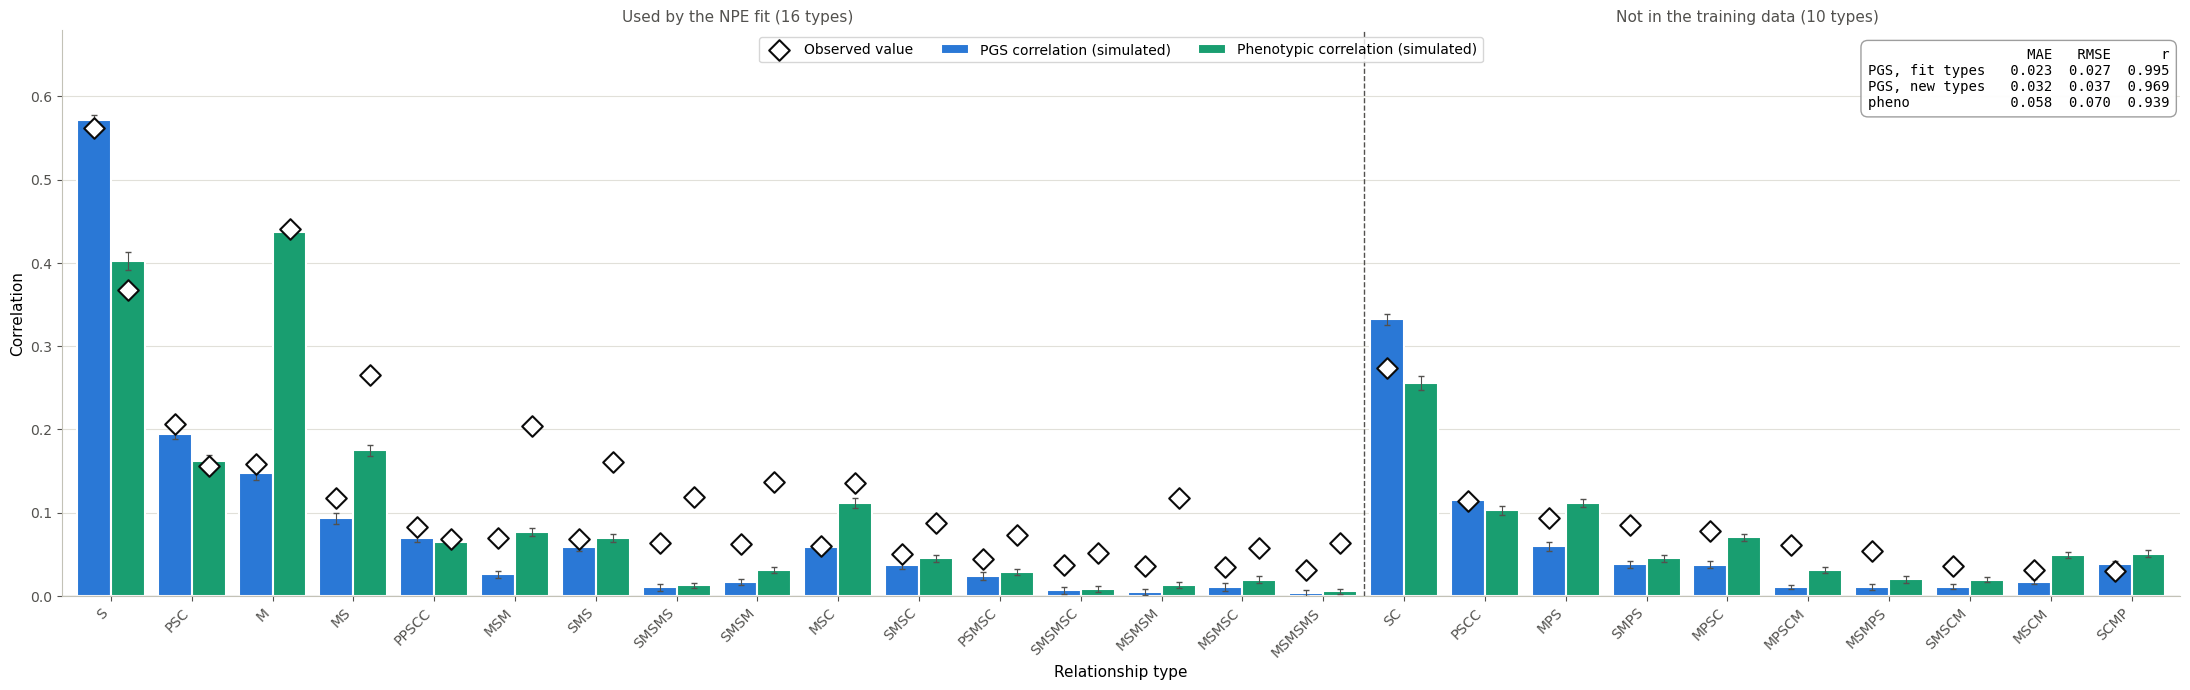


Trait 1 (AE): simulated vs observed


correlations,n,MAE,RMSE,bias,r
"PGS, 16 fit types",16,0.0231,0.0274,-0.0219,0.9951
"PGS, 10 new types",10,0.0322,0.0370,-0.0185,0.9692
"PGS, all 26 types",26,0.0266,0.0314,-0.0206,0.9858
"phenotypic, 16 fit types",16,0.0578,0.0701,-0.0526,0.9389


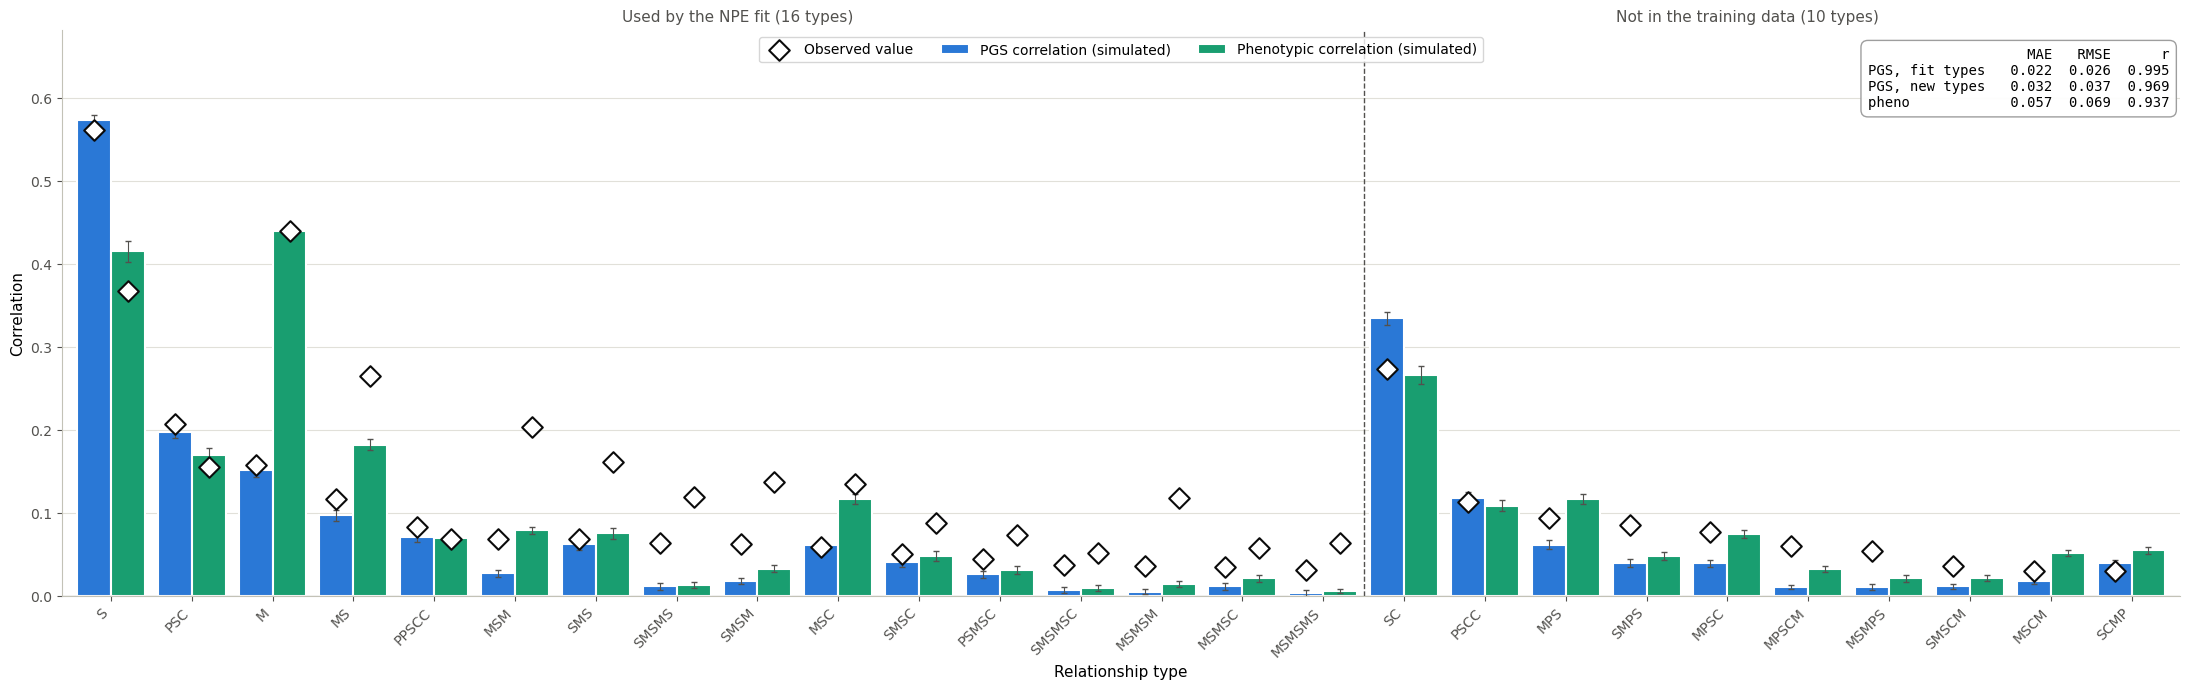


Trait 2 (AFE): simulated vs observed


correlations,n,MAE,RMSE,bias,r
"PGS, 16 fit types",16,0.0217,0.0262,-0.0199,0.9947
"PGS, 10 new types",10,0.0322,0.0368,-0.0170,0.9691
"PGS, all 26 types",26,0.0257,0.0307,-0.0188,0.9853
"phenotypic, 16 fit types",16,0.0567,0.0686,-0.0488,0.9370


In [4]:
plot_condition("01DirAM")

## Condition 02 — AE latent AM (trait 1 = EA)

Trait 1 is EA (AE model: a PGS part and a latent genetic part plus unique environment). Mating is
phenotypic assortative mating on trait 2, a fully latent factor (no PGS) that is genetically (`rg`) and
environmentally (`re`) correlated with EA. No vertical transmission, no shared family environment. NPE
fit: `02AElatentAM`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `am11`, `am12`, `am21` | assortative mating (spousal correlations) | 0 |
| `f11`, `f22`, `f12`, `f21` | vertical transmission | 0 |
| `prop_h2_latent2` | share of trait-2 genetic variance not captured by a PGS | 1 |
| `vg2` | sets the trait-2 environmental variance 1 − `vg2` | 0.5 |
| `s11`, `s12`, `s21`, `s22` | shared family environment (no effect: the engine ignores `s`) | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 20 (analysed 17–19) |
| iterations | simulation replicates | 100 |

**Estimated parameters:**

In [5]:
parameter_table("02AElatentAM")

02AElatentAM: 0.0% of the unrestricted posterior inside the simulated range -> mcmc sampling (20,000 draws)


NPE fit,parameter,meaning,EA4 estimate,posterior SD,95% interval,simulated range,position in range,old PGS (v2)
02AElatentAM,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.7929,0.0461,0.696 – 0.887,0.30 – 0.90,82%,0.8404
02AElatentAM,vg1,sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1)),0.2285,0.0296,0.201 – 0.309,0.20 – 0.80,5%,0.2197
02AElatentAM,re,environmental correlation between the traits,0.5523,0.0309,0.450 – 0.595,0.00 – 0.60,92%,0.5461
02AElatentAM,am22,spousal correlation on trait 2,0.7451,0.0041,0.735 – 0.750,0.25 – 0.75,99%,0.7469
02AElatentAM,rg,genetic correlation between the traits,0.8219,0.0249,0.779 – 0.887,0.20 – 0.90,89%,0.8125


None of the unrestricted posterior lies inside the simulated range; `am22` sits at the upper end of
it and `vg1` at the lower end.

Condition 02 — AE latent AM: results_npe_unweighted_02AElatentAM/predictions/summary_statistics_02AElatentAM_ea4new.csv (100 replicates)


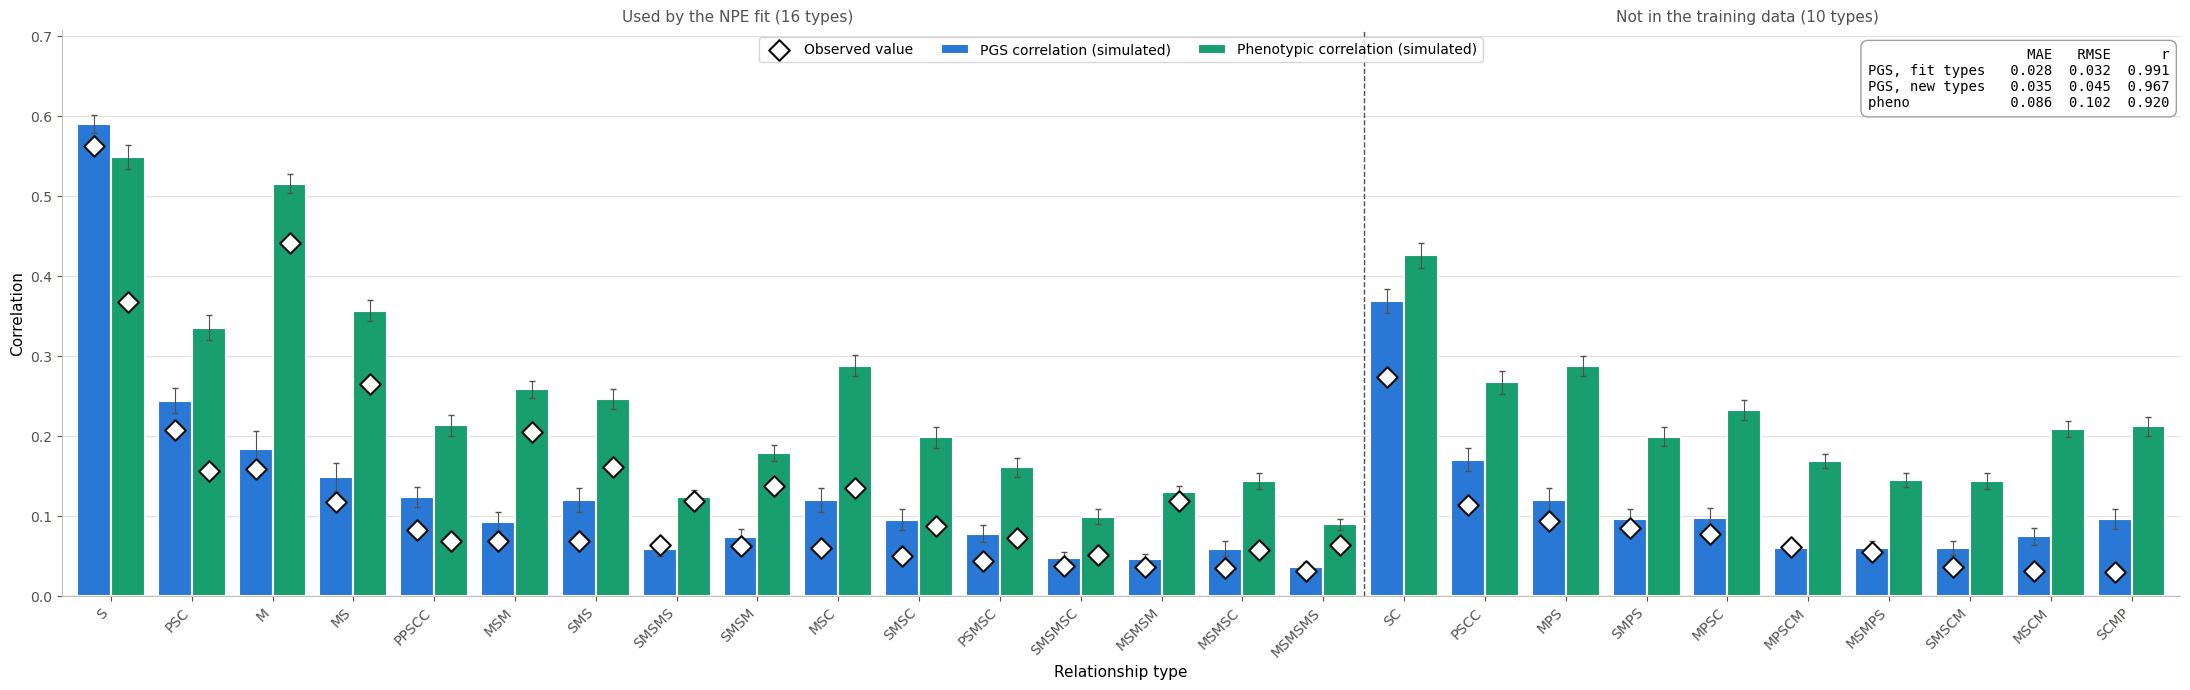


Trait 1 (EA): simulated vs observed


correlations,n,MAE,RMSE,bias,r
"PGS, 16 fit types",16,0.0276,0.0320,0.0269,0.9912
"PGS, 10 new types",10,0.0348,0.0449,0.0346,0.9670
"PGS, all 26 types",26,0.0304,0.0375,0.0299,0.9817
"phenotypic, 16 fit types",16,0.0862,0.1017,0.0862,0.9203


In [6]:
plot_condition("02AElatentAM")

## Condition 03 — Environmental latent AM (trait 1 = EA)

As condition 02 (mating on the fully latent trait 2, genetically correlated with EA), plus within-trait
vertical transmission on both traits (`f11`, `f22`) and shared family environment (`s = 0.5`, which the
engine ignores); the environmental correlation is fixed at `re = 0.1` and `prop_h2_latent1` at 0.7.
NPE fit: `03EnvLatentAM` (training data `nn_training_03EnvLatentAM_all.csv`).

| Fixed parameter | Meaning | Value |
|---|---|---|
| `prop_h2_latent1` | share of trait-1 genetic variance not captured by the PGS | 0.7 |
| `re` | environmental correlation between the traits | 0.1 |
| `am11`, `am12`, `am21` | assortative mating (spousal correlations) | 0 |
| `prop_h2_latent2` | share of trait-2 genetic variance not captured by a PGS | 1 |
| `vg2` | sets the trait-2 environmental variance 1 − `vg2` | 0.5 |
| `s11`, `s12`, `s21`, `s22` | shared family environment (no effect: the engine ignores `s`) | 0.5 |
| `f12`, `f21` | cross-trait vertical transmission | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 20 (analysed 17–19) |
| iterations | simulation replicates | 100 |

**Estimated parameters:**

In [7]:
parameter_table("03EnvLatentAM")

03EnvLatentAM: 0.0% of the unrestricted posterior inside the simulated range -> mcmc sampling (20,000 draws)


NPE fit,parameter,meaning,EA4 estimate,posterior SD,95% interval,simulated range,position in range,old PGS (v2)
03EnvLatentAM,vg1,sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1)),0.7078,0.0763,0.593 – 0.799,0.40 – 0.80,77%,0.7138
03EnvLatentAM,f11,"vertical transmission, trait 1",0.2131,0.0666,0.082 – 0.253,0.05 – 0.30,65%,0.0938
03EnvLatentAM,f22,"vertical transmission, trait 2",0.0598,0.0031,0.054 – 0.064,0.05 – 0.30,4%,0.0543
03EnvLatentAM,am22,spousal correlation on trait 2,0.7357,0.0071,0.720 – 0.746,0.25 – 0.75,97%,0.7329
03EnvLatentAM,rg,genetic correlation between the traits,0.8981,0.0014,0.895 – 0.900,0.30 – 0.90,100%,0.8955


None of the unrestricted posterior lies inside the simulated range: `rg` and `am22` sit at the upper
end of it with very small posterior SDs. The [last section](#why-condition-03-fits-poorly) explains
why these estimates fit poorly.

Condition 03 — Environmental latent AM: results_npe_unweighted_03EnvLatentAM/predictions/summary_statistics_03EnvLatentAM_ea4new.csv (100 replicates)


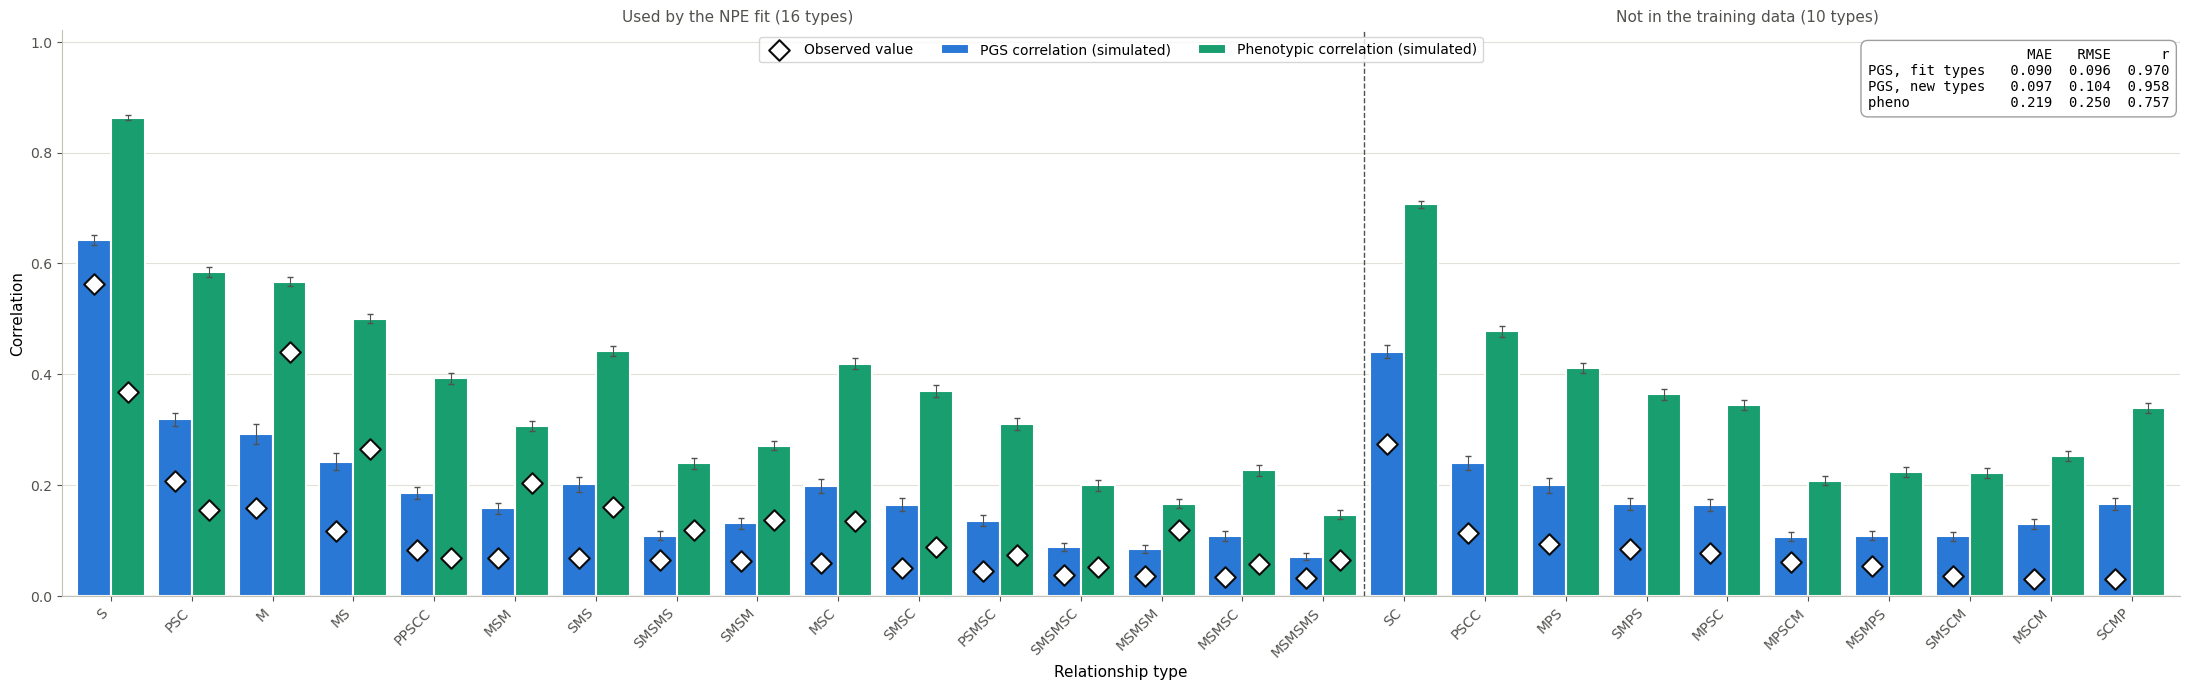


Trait 1 (EA): simulated vs observed


correlations,n,MAE,RMSE,bias,r
"PGS, 16 fit types",16,0.0904,0.0961,0.0904,0.9703
"PGS, 10 new types",10,0.0973,0.1037,0.0973,0.9581
"PGS, all 26 types",26,0.0930,0.0991,0.0930,0.9619
"phenotypic, 16 fit types",16,0.2187,0.2505,0.2187,0.7569


In [8]:
plot_condition("03EnvLatentAM")

## Condition 04 — EA-driven migration (trait 1 = EA)

EA is additive genetics (a PGS part and a latent part) plus unique environment: no assortative mating
(random mating within islands), no vertical transmission, no shared environment. There are 5 islands;
each generation a fraction `move_p` of each sex on each island migrates, and the movers are sorted on EA,
so high-EA movers end up on the high-numbered islands. The population starts from random founders and
runs `n_gen` generations. Trait 2 is an inert dummy required by the bivariate engine. NPE fit:
`04EAmigration`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `vg2` | dummy trait 2: environmental variance 1 − `vg2` | 0.5 |
| `prop_h2_latent2` | dummy trait 2: fully latent | 1 |
| `rg`, `re` | genetic and environmental correlation between the traits | 0 |
| `f11`, `f12`, `f21`, `f22` | vertical transmission | 0 |
| `am11`, `am12`, `am21`, `am22` | assortative mating (spousal correlations) | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | `n_gen` = 4 (analysed 1–3) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (`n_gen`: posterior mode; the old-PGS run also had `n_gen` = 4):

In [9]:
parameter_table("04EAmigration")

04EAmigration: 100.0% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)


NPE fit,parameter,meaning,EA4 estimate,posterior SD,95% interval,simulated range,position in range,old PGS (v2)
04EAmigration,move_p,fraction of each sex per island migrating each generation,0.4541,0.0042,0.446 – 0.462,0.01 – 0.70,64%,0.4538
04EAmigration,n_gen,generations since the random founders (categorical posterior),4.0000,0.0000,4.000 – 4.000,3.00 – 10.00,14%,4.0002
04EAmigration,vg1,sets the trait-1 environmental variance 1 − vg1 (founder h² ≈ 1/(2 − vg1)),0.3118,0.0336,0.248 – 0.383,0.20 – 0.80,19%,0.3069
04EAmigration,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.7132,0.0268,0.661 – 0.770,0.30 – 0.90,69%,0.7763


The whole posterior lies inside the simulated range (plain rejection sampling). The observed
correlations are nonetheless outside the simulated distribution jointly (see the table in the next
section), so the very narrow posterior intervals are overconfident.

Condition 04 — EA-driven migration: results_npe_unweighted_04EAmigration/predictions/summary_statistics_04EAmigration_ea4new.csv (100 replicates)


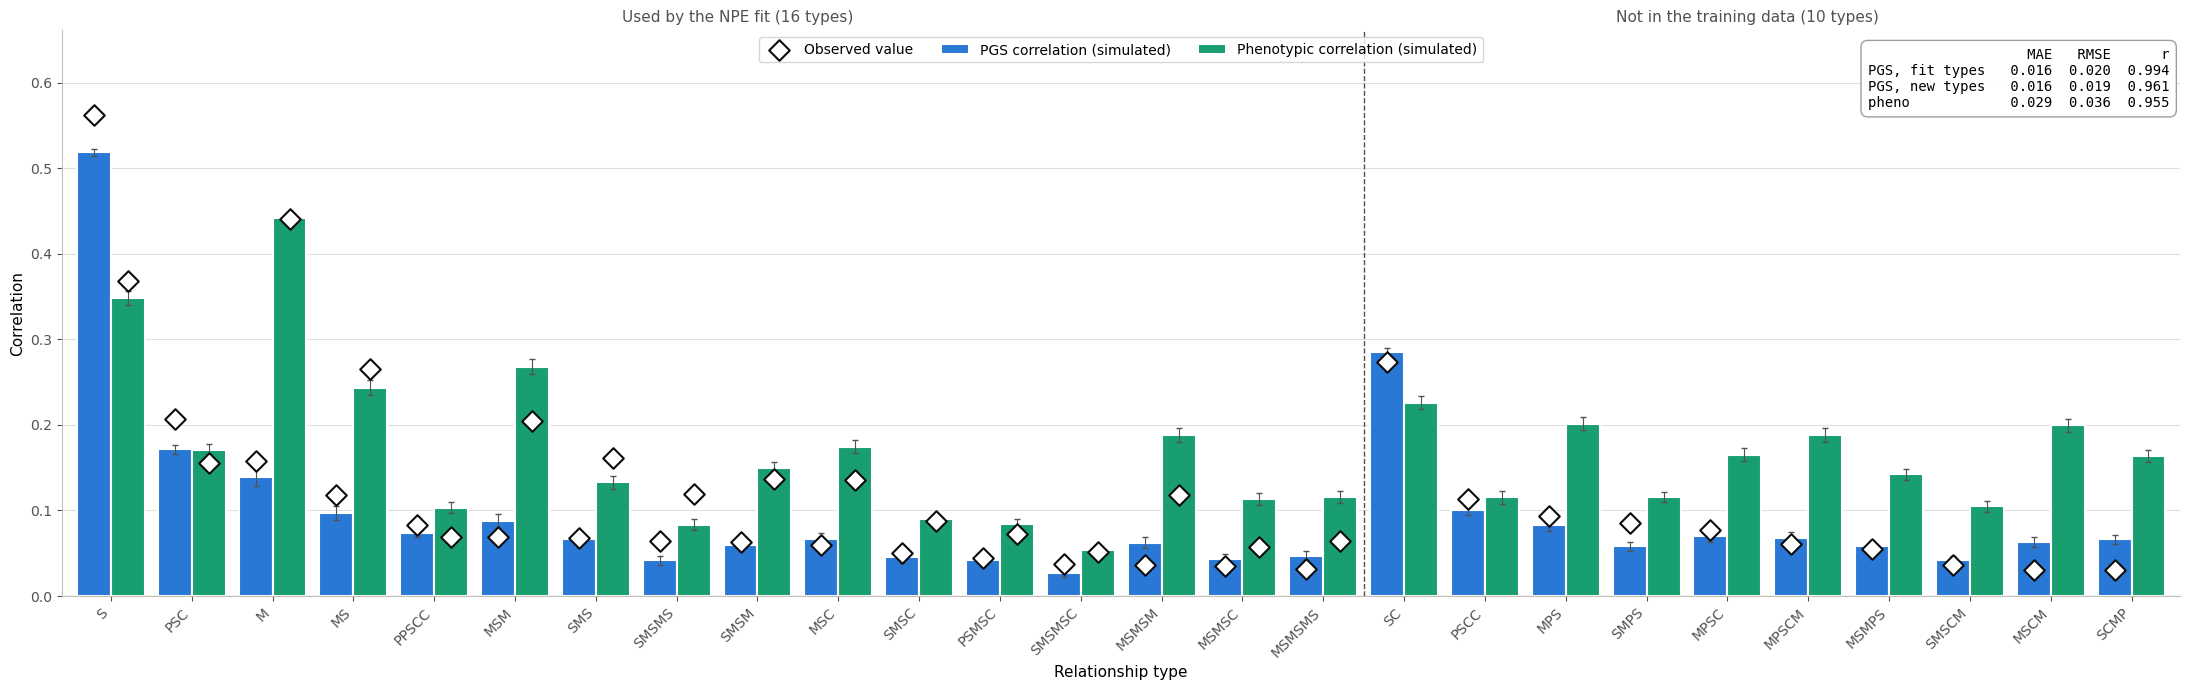


Trait 1 (EA): simulated vs observed


correlations,n,MAE,RMSE,bias,r
"PGS, 16 fit types",16,0.0156,0.0195,-0.0060,0.9935
"PGS, 10 new types",10,0.0158,0.0193,0.0039,0.9611
"PGS, all 26 types",26,0.0157,0.0194,-0.0022,0.9870
"phenotypic, 16 fit types",16,0.0289,0.0361,0.0158,0.9553


In [10]:
plot_condition("04EAmigration")

## Why condition 03 fits poorly

Two problems add up.

1. **The model cannot produce EA's phenotypic pattern.** Spouses are more alike on EA than siblings
   (0.44 vs 0.37). In condition 03, every simulation with a spousal EA correlation of 0.40 or more has a
   sibling correlation of at least 0.61, and the observed sibling correlation is below that of every one
   of the 38,124 training simulations.
2. **The NPE estimate is not the best the model can do.** Because the observed data lie outside what
   the model produces, the NPE extrapolates. Simulated at its estimate, condition 03 fits worse than
   99% of its own training simulations. The best training simulations fit the PGS correlations
   closely (MAE about 0.01); their remaining misfit is the phenotypic one of point 1.

The cells below give the evidence. They use the training data of each NPE fit (the
`nn_training_*.csv` files and row filters of `run_npe_pipeline.py`) and the 20–30 features each
fit uses (`run_specs/<fit>/features.txt`). They compare each condition's observed data with its training
simulations, with the simulation at the EA4 estimate, and with the best-fitting training simulation
(smallest MAE over the fit's features). A training simulation is a single replicate, so the best of
~20,000 of them is slightly favoured by noise; the predicted condition averages 100 replicates.

In [11]:
# training data of each NPE fit, as in run_npe_pipeline.py (RUNS): file and row filter
TRAINING = {"01DirAM_AE": ("01DirAM", "param_vg2.notna()"), "01DirAM_AFE": ("01DirAM", "param_vg2.notna()"),
            "02AElatentAM": ("02AElatentAM", None), "03EnvLatentAM": ("03EnvLatentAM_all", None),
            "04EAmigration": ("04EAmigration", None)}
SUMMARY_OF = {"01DirAM_AE": "01DirAM_AE", "01DirAM_AFE": "01DirAM_AE", "02AElatentAM": "02AElatentAM",
              "03EnvLatentAM": "03EnvLatentAM", "04EAmigration": "04EAmigration"}
_training_files = {}


def features(fit):
    return (script_dir / "run_specs" / fit / "features.txt").read_text().split()


def fit_params(fit):
    return (script_dir / "run_specs" / fit / "params.txt").read_text().split()


def training_data(fit):
    """Training simulations of an NPE fit with all its features present."""
    data, row_filter = TRAINING[fit]
    if data not in _training_files:
        _training_files[data] = pd.read_csv(script_dir / f"nn_training_{data}.csv")
    d = _training_files[data]
    return (d.query(row_filter) if row_filter else d).dropna(subset=features(fit))


def observed(feats):
    """Observed values of NPE features such as S_PGS1 or M_Y2 (EA4 PGS; phenotypic)."""
    return pd.Series({f: (obs_pgs if "_PGS" in f else obs_pheno)[f.rsplit("_", 1)[0]] for f in feats})


def simulated(fit, feats):
    """Mean over replicates of the predicted condition at the EA4 estimate, for an NPE fit's features."""
    s = pd.read_csv(pred_path(SUMMARY_OF[fit]))
    return pd.Series({f"{r.RelationshipPath}_{r.Variable}": r.Correlation_Mean for r in s.itertuples()})[feats]


rows = []
for fit in TRAINING:
    feats = features(fit)
    d, obs = training_data(fit), observed(feats)
    X = d[feats]
    mean, prec = X.mean().to_numpy(), np.linalg.pinv(np.cov(X.to_numpy(), rowvar=False))

    def mahalanobis(v):
        z = np.atleast_2d(v - mean)
        return np.sqrt(np.einsum("ij,jk,ik->i", z, prec, z))

    mae = (X - obs).abs().mean(axis=1)
    est_mae = (simulated(fit, feats) - obs).abs().mean()
    outside = [f"{f} ({obs[f]:.3f}; simulated {X[f].min():.3f}–{X[f].max():.3f})"
               for f in feats if not X[f].min() <= obs[f] <= X[f].max()]
    rows.append({"NPE fit": fit, "training simulations": len(d), "features": len(feats),
                 "Mahalanobis: observed": mahalanobis(obs.to_numpy())[0],
                 "Mahalanobis: training max": mahalanobis(X.to_numpy()).max(),
                 "observed outside the simulated range": "; ".join(outside) or "–",
                 "MAE: best training simulation": mae.min(),
                 "MAE: at the EA4 estimate": est_mae,
                 "simulations fitting better than the estimate": f"{(mae < est_mae).mean():.1%}"})
show(pd.DataFrame(rows), precision=3)

NPE fit,training simulations,features,Mahalanobis: observed,Mahalanobis: training max,observed outside the simulated range,MAE: best training simulation,MAE: at the EA4 estimate,simulations fitting better than the estimate
01DirAM_AE,19593,20,20.773,10.554,–,0.022,0.025,0.5%
01DirAM_AFE,19593,20,14.392,9.183,–,0.025,0.025,0.0%
02AElatentAM,18138,20,22.070,9.870,–,0.021,0.048,24.3%
03EnvLatentAM,38124,20,22.416,10.645,S_Y1 (0.367; simulated 0.370–0.923),0.032,0.137,99.0%
04EAmigration,19968,30,27.221,11.058,–,0.021,0.022,0.1%


- **All four conditions are out of distribution jointly.** The observed data are 14–27 Mahalanobis
  units from the training mean, while no training simulation is further than ~11. No model reproduces
  the observed correlation pattern exactly, so being out of distribution alone does not explain 03.
- **Only in 03 does a single observed correlation fall outside the simulated range:** the sibling
  phenotypic correlation `S_Y1`.
- **For 01 and 04, the simulation at the estimate fits about as well as the best training simulation.**
  For 02 it is worse than about a quarter of the training simulations, and for 03 worse than 99% of them.

### The spousal–sibling trade-off

The figure plots every training simulation of conditions 02 and 03 by its spousal (`M_Y1`) and sibling
(`S_Y1`) phenotypic EA correlation, with the observed values, the simulation at the EA4 estimate and the
best-fitting training simulation.

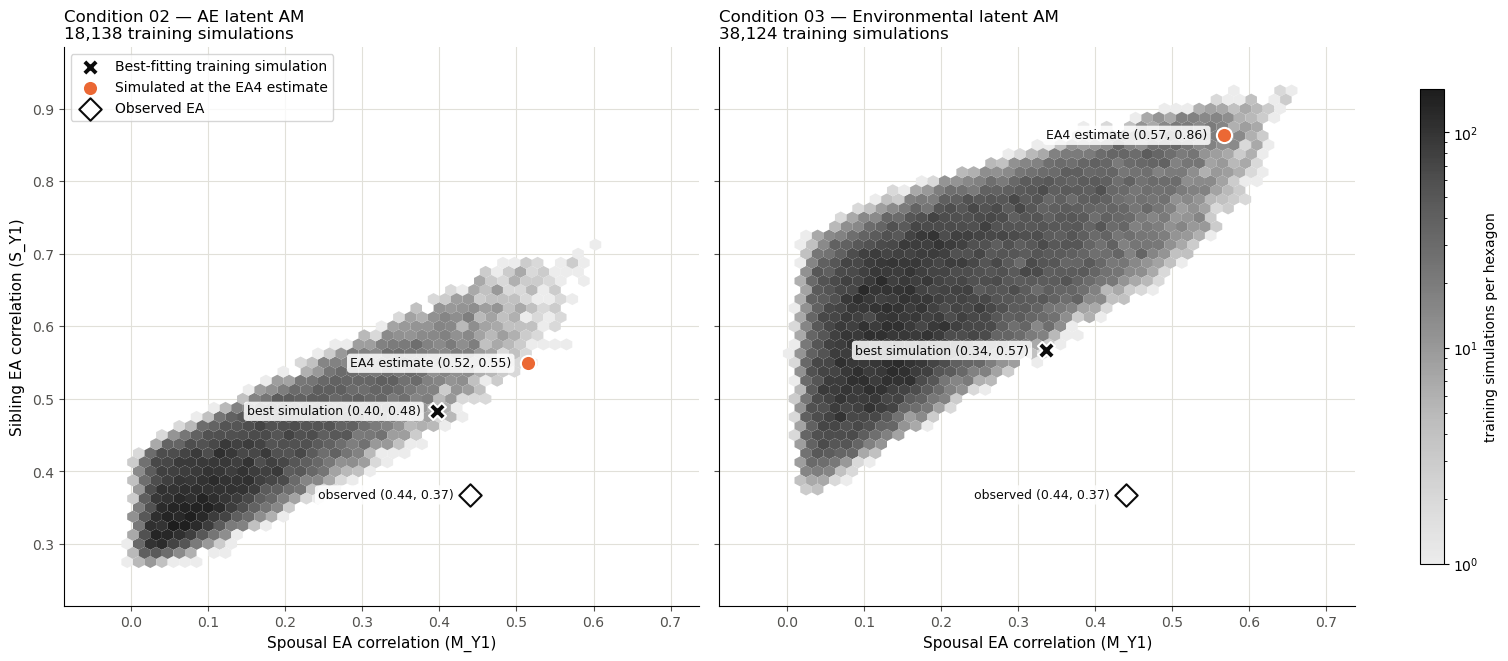

In [12]:
# grey ramp from light grey (one simulation) to near-black, so sparse hexagons stay visible
DENSITY = LinearSegmentedColormap.from_list("density", plt.cm.Greys(np.linspace(0.15, 0.9, 256)))
SHORT_LABEL = {"Best-fitting training simulation": "best simulation", "Simulated at the EA4 estimate": "EA4 estimate",
               "Observed EA": "observed"}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
hexbins = []
for ax, fit in zip(axes, ("02AElatentAM", "03EnvLatentAM")):
    feats = features(fit)
    d, obs = training_data(fit), observed(feats)
    best = d.loc[(d[feats] - obs).abs().mean(axis=1).idxmin()]
    est = simulated(fit, feats)
    hexbins.append(ax.hexbin(d["M_Y1"], d["S_Y1"], gridsize=50, cmap=DENSITY, mincnt=1, linewidths=0,
                             extent=(-0.05, 0.7, 0.25, 0.95)))
    points = (("Best-fitting training simulation", best, dict(marker="X", s=150, color=INK)),
              ("Simulated at the EA4 estimate", est, dict(marker="o", s=120, color=ACCENT)),
              ("Observed EA", obs, dict(marker="D", s=130, facecolor="white", edgecolor=INK)))
    for label, p, style in points:
        style = {"edgecolor": "white", **style}
        ax.scatter(p["M_Y1"], p["S_Y1"], linewidth=1.5, zorder=5, label=label, **style)
        ax.annotate(f"{SHORT_LABEL[label]} ({p['M_Y1']:.2f}, {p['S_Y1']:.2f})", (p["M_Y1"], p["S_Y1"]),
                    xytext=(-12, 0), textcoords="offset points", ha="right", va="center", fontsize=9,
                    color=INK, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.85))
    ax.set_title(f"{CONDITIONS[fit]['title']}\n{len(d):,} training simulations", loc="left", fontsize=12)
    ax.set_xlabel("Spousal EA correlation (M_Y1)", fontsize=11)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("Sibling EA correlation (S_Y1)", fontsize=11)
axes[0].legend(loc="upper left", fontsize=10, frameon=True)
norm = LogNorm(vmin=1, vmax=max(h.get_array().max() for h in hexbins))
for h in hexbins:
    h.set_norm(norm)
fig.colorbar(hexbins[-1], ax=axes, label="training simulations per hexagon", shrink=0.85)
plt.show()

In both conditions the cloud rises to the right: simulations whose spouses are more alike also have
more alike siblings. The observed point (spouses 0.44, siblings 0.37) lies below both clouds, far
below the 03 cloud, while the 03 estimate lands at the opposite, upper-right end of that cloud.

**Why the model produces this trade-off.** In condition 03, EA has no assortative mating of its own:
spouses resemble each other on EA only because they mate on trait 2, which is correlated with EA. With
`re` fixed at 0.1, that correlation is almost entirely genetic (`rg`). A high spousal EA correlation
therefore needs strong mating on trait 2 and a high genetic correlation (`am22` and `rg`, the parameters
`M_Y1` depends on most), and mating on a trait that shares EA's genes is genetic assortment on EA. It
raises the genetic resemblance of all relatives, siblings included. The design adds a heritability of at
least about 0.63 (`vg1` ≥ 0.4) and vertical transmission on EA (`f11` ≥ 0.05), the strongest driver of
the sibling correlation in these simulations.

In condition 02, `re` is estimated (0–0.6): an environmental correlation between EA and the mating trait
makes spouses alike on EA without making their relatives genetically alike (`re` is correlated with
`M_Y1` but not with `S_Y1` below). `vg1` also goes down to 0.2, and there is no vertical transmission.
02's best simulations come closer to the observed pattern, but no 02 simulation reaches it either.

In [13]:
rows = []
for fit in ("02AElatentAM", "03EnvLatentAM"):
    d = training_data(fit)
    for target in ("M_Y1", "S_Y1"):
        rows.append({"condition": fit, "correlation of": target,
                     **{p: np.corrcoef(d[target], d[f"param_{p}"])[0, 1] for p in fit_params(fit)}})
print("Correlation of the spousal and sibling EA correlations with each parameter across the training simulations:")
show(pd.DataFrame(rows), precision=2)

for fit in ("02AElatentAM", "03EnvLatentAM"):
    d = training_data(fit)
    high = d[d["M_Y1"] >= 0.40]
    print(f"{fit}: {len(high):,} of {len(d):,} simulations have M_Y1 >= 0.40; their S_Y1 is "
          f"{high['S_Y1'].min():.3f} or more (median {high['S_Y1'].median():.3f}), with am22 >= "
          f"{high['param_am22'].min():.2f} and rg >= {high['param_rg'].min():.2f}. "
          f"Lowest S_Y1 of all simulations: {d['S_Y1'].min():.3f} (observed {obs_pheno['S']:.3f}).")

Correlation of the spousal and sibling EA correlations with each parameter across the training simulations:


condition,correlation of,prop_h2_latent1,vg1,re,am22,rg,f11,f22
02AElatentAM,M_Y1,0.00,0.07,0.20,0.57,0.73,–,–
02AElatentAM,S_Y1,-0.00,0.55,-0.01,0.47,0.62,–,–
03EnvLatentAM,M_Y1,–,0.06,–,0.72,0.63,0.10,0.05
03EnvLatentAM,S_Y1,–,0.26,–,0.42,0.42,0.74,0.01


02AElatentAM: 817 of 18,138 simulations have M_Y1 >= 0.40; their S_Y1 is 0.466 or more (median 0.588), with am22 >= 0.55 and rg >= 0.60. Lowest S_Y1 of all simulations: 0.274 (observed 0.367).
03EnvLatentAM: 4,109 of 38,124 simulations have M_Y1 >= 0.40; their S_Y1 is 0.611 or more (median 0.792), with am22 >= 0.52 and rg >= 0.47. Lowest S_Y1 of all simulations: 0.370 (observed 0.367).


### The NPE estimate versus the best training simulations

The NPE was trained only on simulated data. At observed data the model cannot produce, its posterior is
an extrapolation. None of the unrestricted posterior lies inside the simulated range, and the
range-restricted MCMC piles it against the upper ends of `am22` and `rg` with very small SDs: a
boundary effect, not precision. The table compares that estimate with the five best-fitting training
simulations, which all have low `vg1` and `f11`.

In [14]:
fit = "03EnvLatentAM"
feats, params = features(fit), fit_params(fit)
d, obs = training_data(fit), observed(feats)
pgs_f, ph_f = [f for f in feats if "_PGS" in f], [f for f in feats if "_Y" in f]
shown = ["S_Y1", "PSC_Y1", "M_Y1", "MS_Y1", "S_PGS1", "M_PGS1"]


def fit_summary(values):
    r = values[feats].astype(float) - obs
    return {"MAE": r.abs().mean(), "PGS MAE": r[pgs_f].abs().mean(), "pheno MAE": r[ph_f].abs().mean(),
            **values[shown].astype(float)}


estimate = pd.read_csv(script_dir / f"results_npe_unweighted_{fit}" / "predictions_ea4new" /
                       "posterior_summary.csv").set_index("parameter")["mean"]
mae = (d[feats] - obs).abs().mean(axis=1)
rows = [{"": "observed", **obs[shown]},
        {"": "simulated at the EA4 estimate (100 replicates)", **estimate[params],
         **fit_summary(simulated(fit, feats))}]
for i in mae.nsmallest(5).index:
    rows.append({"": f"training simulation {d.loc[i, 'Condition']}",
                 **{p: d.loc[i, f"param_{p}"] for p in params}, **fit_summary(d.loc[i])})
table = pd.DataFrame(rows)
show(table[["", *params, "MAE", "PGS MAE", "pheno MAE", *shown]], precision=3)

# training simulations whose parameters are all within 10% of the simulated range of the estimate
cfg = json.loads((script_dir / f"results_npe_unweighted_{fit}" / "config.json").read_text())
width = pd.Series(cfg["prior_upper"], cfg["prior_params"]) - pd.Series(cfg["prior_lower"], cfg["prior_params"])
near = d[np.all([(d[f"param_{p}"] - estimate[p]).abs() <= 0.1 * width[p] for p in params], axis=0)]
print(f"{len(near)} training simulations lie within 10% of the range of the estimate on every parameter; "
      f"their median S_Y1 is {near['S_Y1'].median():.3f}, M_Y1 {near['M_Y1'].median():.3f}, "
      f"S_PGS1 {near['S_PGS1'].median():.3f}, M_PGS1 {near['M_PGS1'].median():.3f}.")

,vg1,f11,f22,am22,rg,MAE,PGS MAE,pheno MAE,S_Y1,PSC_Y1,M_Y1,MS_Y1,S_PGS1,M_PGS1
observed,–,–,–,–,–,–,–,–,0.367,0.156,0.440,0.265,0.562,0.158
simulated at the EA4 estimate (100 replicates),0.708,0.213,0.060,0.736,0.898,0.137,0.090,0.322,0.863,0.584,0.567,0.501,0.642,0.292
training simulation Condition_17164,0.471,0.053,0.219,0.544,0.893,0.032,0.011,0.116,0.567,0.309,0.336,0.269,0.571,0.150
training simulation Condition_19547,0.463,0.051,0.115,0.628,0.699,0.033,0.011,0.119,0.556,0.285,0.306,0.241,0.575,0.150
training simulation Condition_09993,0.410,0.056,0.183,0.670,0.659,0.034,0.012,0.119,0.545,0.297,0.296,0.253,0.550,0.120
training simulation Condition_17859,0.413,0.056,0.155,0.644,0.644,0.034,0.012,0.120,0.545,0.285,0.296,0.234,0.558,0.123
training simulation Condition_02865,0.459,0.056,0.207,0.541,0.892,0.034,0.013,0.118,0.572,0.306,0.326,0.267,0.573,0.159


6 training simulations lie within 10% of the range of the estimate on every parameter; their median S_Y1 is 0.858, M_Y1 0.558, S_PGS1 0.637, M_PGS1 0.290.


- **The predicted-condition simulation is consistent with the training data.** Training simulations
  near the estimate give the same correlations, so the simulation is right; the estimate is the problem.
- **The estimate moves away from the data.** Compared with the best simulations, it has higher `vg1`
  and `f11`, which raise the sibling correlation further. Its PGS correlations are about 0.09 too high,
  against about 0.01 for the best simulations.
- **The best simulations still miss the phenotypic correlations** (sibling 0.55–0.57 against 0.37):
  that part of the misfit belongs to the model, not to the NPE.
- **The September fit, with an embedding network, extrapolated differently:** `vg1` 0.45, `f11` 0.06,
  close to these best simulations.

**What would help.**
- **Do not read the 03 posterior means as estimates.** Its posterior is driven by the range boundary,
  not by the data. The best-fitting simulations are a better guide to where condition 03 comes closest.
- **The wider-prior design may still not fit.** `Scripts/run_rc_paper_wider` lets `vg1` go down to
  0.05 and `f11` to 0, which lowers the sibling correlation. It still fixes `re` = 0.1, though, so a
  high spousal correlation still has to come from genetic assortment, and with lower heritability that
  route gets weaker. These results point to estimating `re`, as condition 02 does.